Shape: (39105, 6)
label
Real    21197
Fake    17908
Name: count, dtype: int64


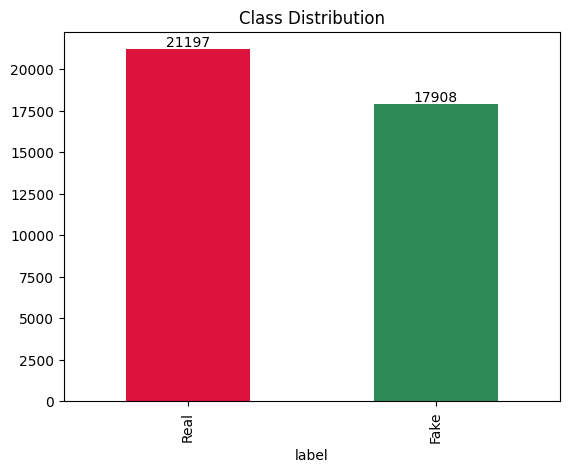

In [1]:
import pandas as pd, numpy as np, glob, re
import matplotlib.pyplot as plt, seaborn as sns

fake_path = glob.glob('/kaggle/input/**/Fake.csv', recursive=True)[0]
true_path = glob.glob('/kaggle/input/**/True.csv', recursive=True)[0]

fake = pd.read_csv(fake_path); fake['label'] = 0
true = pd.read_csv(true_path); true['label'] = 1

df = pd.concat([fake, true], ignore_index=True)
df['content'] = df['title'].fillna('') + ' ' + df['text'].fillna('')
df = df.drop_duplicates(subset='content').reset_index(drop=True)

print("Shape:", df.shape)
counts = df['label'].value_counts().rename({0: 'Fake', 1: 'Real'})
print(counts)

ax = counts.plot(kind='bar', color=['crimson', 'seagreen'], title='Class Distribution')
for i, v in enumerate(counts): ax.text(i, v, str(v), ha='center', va='bottom')
plt.show()

In [2]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def clean_text(t):
    t = t.lower()
    t = re.sub(r'\(reuters\)', ' ', t)      # remove source giveaway
    t = re.sub(r'http\S+|www\S+', ' ', t)   # remove URLs
    t = re.sub(r'[^a-z\s]', ' ', t)         # keep letters only
    tokens = t.split()                       # tokenization
    tokens = [w for w in tokens if w not in ENGLISH_STOP_WORDS and len(w) > 2]  # stop word removal
    return ' '.join(tokens)

df['clean'] = df['content'].apply(clean_text)
print("Before:", df['content'][0][:200])
print("After :", df['clean'][0][:200])

Before:  Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out
After : donald trump sends embarrassing new year eve message disturbing donald trump just couldn wish americans happy new year leave instead shout enemies haters dishonest fake news media reality star just jo


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X_train, X_test, y_train, y_test = train_test_split(
    df['clean'], df['label'], test_size=0.2, random_state=42, stratify=df['label'])

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)
print("Train:", X_train_vec.shape, "| Test:", X_test_vec.shape)

Train: (31284, 5000) | Test: (7821, 5000)


Logistic Regression: 98.31%
Naive Bayes: 94.00%
Random Forest: 98.18%


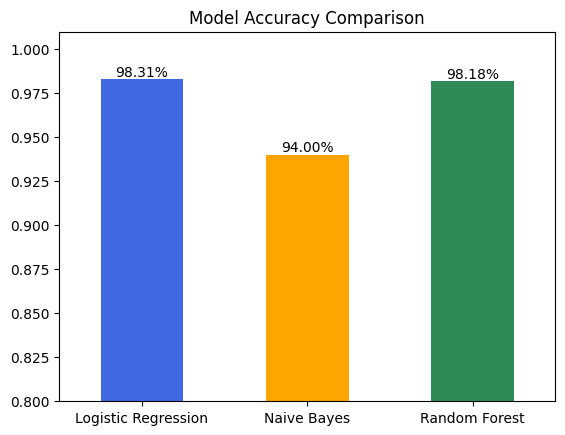


Best model: Logistic Regression


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Naive Bayes': MultinomialNB(),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train_vec, y_train)
    results[name] = accuracy_score(y_test, m.predict(X_test_vec))
    print(f"{name}: {results[name]*100:.2f}%")

ax = pd.Series(results).plot(kind='bar', color=['royalblue', 'orange', 'seagreen'],
                             ylim=(0.8, 1.01), title='Model Accuracy Comparison')
for i, v in enumerate(results.values()): ax.text(i, v, f"{v*100:.2f}%", ha='center', va='bottom')
plt.xticks(rotation=0); plt.show()

best_name = max(results, key=results.get)
best_model = models[best_name]
print("\nBest model:", best_name)

              precision    recall  f1-score   support

        Fake       0.99      0.97      0.98      3582
        Real       0.98      0.99      0.98      4239

    accuracy                           0.98      7821
   macro avg       0.98      0.98      0.98      7821
weighted avg       0.98      0.98      0.98      7821

Confusion matrix:
 [[3489   93]
 [  39 4200]]
Correct: 7689 | Wrong: 132


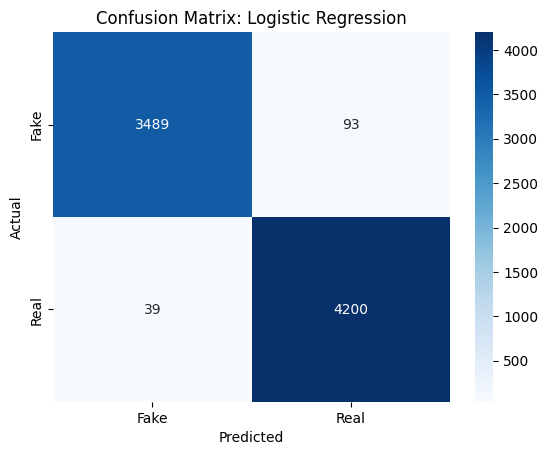

In [5]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = best_model.predict(X_test_vec)
print(classification_report(y_test, y_pred, target_names=['Fake', 'Real']))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)
print(f"Correct: {cm[0,0]+cm[1,1]} | Wrong: {cm[0,1]+cm[1,0]}")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Real'], yticklabels=['Fake', 'Real'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Confusion Matrix: {best_name}')
plt.show()

In [6]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def predict_news(text):
    vec = tfidf.transform([clean_text(text)])
    pred = best_model.predict(vec)[0]
    conf = best_model.predict_proba(vec)[0].max() * 100
    return ("REAL NEWS" if pred == 1 else "FAKE NEWS"), conf

box = widgets.Textarea(placeholder='Paste a news headline or article here...',
                       layout=widgets.Layout(width='90%', height='100px'))
btn = widgets.Button(description='Predict', button_style='primary')
out = widgets.Output()

def on_click(_):
    with out:
        clear_output()
        if box.value.strip() == '':
            print("Please enter some text.")
        else:
            label, conf = predict_news(box.value)
            print(f"Prediction: {label}  (confidence: {conf:.1f}%)")

btn.on_click(on_click)
display(box, btn, out)

Textarea(value='', layout=Layout(height='100px', width='90%'), placeholder='Paste a news headline or article h…

Button(button_style='primary', description='Predict', style=ButtonStyle())

Output()